# Image denoising using dictionary learning: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_image_denoising.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_image_denoising.html)).

**Scenario:** the right half of an image is distorted with Gaussian noise. `extract_patches_2d` collects all 7x7
patches of the left half; `MiniBatchDictionaryLearning` learns 50 atoms from them; the noisy right-half patches
are coded with several transform algorithms (OMP 1/2 atoms, LARS, thresholding), decoded and put back with
`reconstruct_from_patches_2d`.

**Adaptations:**
- **Data:** `scipy.datasets.face` needs a download. A deterministic synthetic grey image (64x80: gradient, a
  disc, a bar and a texture) replaces the raccoon face; noise uses `np.random.RandomState(0)` instead of the
  global NumPy stream. The 4x down-sampling step is kept for the synthetic image (generated at 256x320).
- **Dictionary learning is a GAP in Moxie** (`MiniBatchDictionaryLearning` is a raising declaration in
  `moxie.decomposition`). The sklearn dictionary, fitted with an explicit `random_state=0` (the example leaves it
  unseeded), is shared with Moxie as a fixed dictionary `V`. Everything after that runs in Mojo:
  patch extraction, centering, coding with `SparseCoder(V, transform_algorithm="threshold", transform_alpha=0.1)`
  (the example's fourth row), decoding, min/max scaling and `reconstruct_from_patches_2d`.
- **OMP and LARS rows are GAPs:** Moxie's `SparseCoder` implements only `threshold`
  (`decomposition` family); `--expect-fail` cell below.
- **Extra feature_extraction checks:** reconstruction of the *uncoded* noisy patches (an exact inverse check),
  random sub-sampling `extract_patches_2d(..., max_patches=0.05, random_state=0)` and
  `PatchExtractor(patch_size=(7, 7), max_patches=20, random_state=0)` over a two-image batch, all compared value
  for value with sklearn (Moxie reproduces NumPy's legacy `RandomState.randint` stream).

**Determinism:** the official example is stochastic (unseeded noise and dictionary learning); with the seeds
fixed above every compared quantity is deterministic, so parity is numerical.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_extraction/plot_image_denoising")

## 1. scikit-learn (Python reference)

In [2]:
import numpy as np

# Synthetic stand-in for scipy.datasets.face(gray=True) / 255.
yy, xx = np.mgrid[0:256, 0:320] / np.array([256.0, 320.0])[:, None, None]
raccoon_face = 0.25 + 0.4 * xx + 0.1 * yy
raccoon_face[(yy - 0.45) ** 2 + (xx - 0.3) ** 2 < 0.04] = 0.9
raccoon_face[(np.abs(yy - 0.7) < 0.05) & (xx > 0.45)] = 0.1
raccoon_face += 0.05 * np.sin(40 * xx) * np.cos(30 * yy)

# downsample for higher speed (official example)
raccoon_face = (
    raccoon_face[::4, ::4]
    + raccoon_face[1::4, ::4]
    + raccoon_face[::4, 1::4]
    + raccoon_face[1::4, 1::4]
)
raccoon_face /= 4.0
height, width = raccoon_face.shape

print("Distorting image...")
distorted = raccoon_face.copy()
distorted[:, width // 2 :] += 0.075 * np.random.RandomState(0).randn(height, width // 2)

Distorting image...


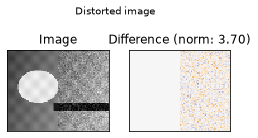

In [3]:
import matplotlib.pyplot as plt


def show_with_diff(image, reference, title):
    """Helper function to display denoising (official example, smaller figure)."""
    plt.figure(figsize=(4, 2.4), dpi=72)
    plt.subplot(1, 2, 1)
    plt.title("Image")
    plt.imshow(image, vmin=0, vmax=1, cmap=plt.cm.gray, interpolation="nearest")
    plt.xticks(())
    plt.yticks(())
    plt.subplot(1, 2, 2)
    difference = image - reference
    plt.title("Difference (norm: %.2f)" % np.sqrt(np.sum(difference**2)))
    plt.imshow(difference, vmin=-0.5, vmax=0.5, cmap=plt.cm.PuOr, interpolation="nearest")
    plt.xticks(())
    plt.yticks(())
    plt.suptitle(title, size=10)


show_with_diff(distorted, raccoon_face, "Distorted image")

In [4]:
from time import time

from sklearn.feature_extraction.image import extract_patches_2d

print("Extracting reference patches...")
t0 = time()
patch_size = (7, 7)
data = extract_patches_2d(distorted[:, : width // 2], patch_size)
sk_left_patches = data.copy()
data = data.reshape(data.shape[0], -1)
data -= np.mean(data, axis=0)
data /= np.std(data, axis=0)
print(f"{data.shape[0]} patches extracted in %.2fs." % (time() - t0))

from sklearn.decomposition import MiniBatchDictionaryLearning

print("Learning the dictionary...")
t0 = time()
dico = MiniBatchDictionaryLearning(n_components=50, batch_size=200, alpha=1.0, max_iter=10,
                                   random_state=0)  # adaptation: seeded
V = dico.fit(data).components_
dt = time() - t0
print(f"{dico.n_iter_} iterations / {dico.n_steps_} steps in {dt:.2f}.")

Extracting reference patches...
1972 patches extracted in 0.01s.
Learning the dictionary...


8.0 iterations / 78 steps in 3.02.


Extracting noisy patches... 
Orthogonal Matching Pursuit 1 atom done in 0.04s.
Orthogonal Matching Pursuit 2 atoms done in 0.10s.


Least-angle regression 4 atoms done in 0.51s.
Thresholding  alpha=0.1 done in 0.01s.
sampled (98, 7, 7) batch (40, 7, 7)


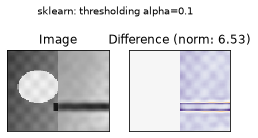

In [5]:
from sklearn.feature_extraction.image import reconstruct_from_patches_2d

print("Extracting noisy patches... ")
data = extract_patches_2d(distorted[:, width // 2 :], patch_size)
sk_noisy_rebuilt = reconstruct_from_patches_2d(data, (height, width // 2))
data = data.reshape(data.shape[0], -1)
intercept = np.mean(data, axis=0)
data -= intercept

transform_algorithms = [
    ("Orthogonal Matching Pursuit\n1 atom", "omp", {"transform_n_nonzero_coefs": 1}),
    ("Orthogonal Matching Pursuit\n2 atoms", "omp", {"transform_n_nonzero_coefs": 2}),
    ("Least-angle regression\n4 atoms", "lars", {"transform_n_nonzero_coefs": 4}),
    ("Thresholding\n alpha=0.1", "threshold", {"transform_alpha": 0.1}),
]

reconstructions = {}
for title, transform_algorithm, kwargs in transform_algorithms:
    reconstructions[title] = raccoon_face.copy()
    t0 = time()
    dico.set_params(transform_algorithm=transform_algorithm, **kwargs)
    code = dico.transform(data)
    patches = np.dot(code, V)
    patches += intercept
    patches = patches.reshape(len(data), *patch_size)
    if transform_algorithm == "threshold":
        patches -= patches.min()
        patches /= patches.max()
    reconstructions[title][:, width // 2 :] = reconstruct_from_patches_2d(patches, (height, width // 2))
    dt = time() - t0
    print(title.replace("\n", " "), "done in %.2fs." % dt)
show_with_diff(reconstructions["Thresholding\n alpha=0.1"], raccoon_face, "sklearn: thresholding alpha=0.1")
sk_threshold_half = reconstructions["Thresholding\n alpha=0.1"][:, width // 2 :]

# Extra checks: random sub-sampling and PatchExtractor on a two-image batch.
from sklearn.feature_extraction.image import PatchExtractor
left, right = np.ascontiguousarray(distorted[:, : width // 2]), np.ascontiguousarray(distorted[:, width // 2 :])
sk_sampled = extract_patches_2d(left, patch_size, max_patches=0.05, random_state=0)
sk_batch = PatchExtractor(patch_size=(7, 7), max_patches=20, random_state=0).transform(np.stack([left, right]))
print("sampled", sk_sampled.shape, "batch", sk_batch.shape)
nb.share(left=left, right=right, V=np.ascontiguousarray(V))

## 2. Moxie (native Mojo)

Patch extraction, centering, threshold coding with the shared dictionary, decoding, scaling and
reconstruction all run in Mojo.

In [6]:
%%mojo denoise
from numojo import NDArray, Shape, zeros
from moxie.decomposition import SparseCoder
from moxie.feature_extraction.image import extract_patches_2d, reconstruct_from_patches_2d, PatchExtractor, PatchLimit
from moxie_nb_io import load, save


def flatten(p: NDArray[DType.float64]) raises -> NDArray[DType.float64]:
    var n = p.shape[0]
    var k = p.shape[1] * p.shape[2]
    var out = zeros[DType.float64](Shape(n, k))
    for i in range(n * k):
        out.unsafe_set(i, p.unsafe_get(i))
    return out^


def main() raises:
    var left = load("left")
    var right = load("right")
    var V = load("V")
    var height = right.shape[0]
    var half = right.shape[1]

    var left_patches = extract_patches_2d(left, (7, 7))
    save("left_patches", left_patches)
    var noisy = extract_patches_2d(right, (7, 7))
    save("noisy_rebuilt", reconstruct_from_patches_2d(noisy, Shape(height, half)))

    # Center the flattened noisy patches (data -= intercept).
    var data = flatten(noisy)
    var n = data.shape[0]
    var k = data.shape[1]
    var intercept = List[Float64](length=k, fill=0.0)
    for i in range(n):
        for j in range(k):
            intercept[j] += data.unsafe_get(i * k + j)
    for j in range(k):
        intercept[j] /= Float64(n)
    for i in range(n):
        for j in range(k):
            data.unsafe_set(i * k + j, data.unsafe_get(i * k + j) - intercept[j])

    # Threshold coding with the shared dictionary, then decode (np.dot(code, V)).
    var coder = SparseCoder(V, transform_algorithm="threshold", transform_alpha=0.1)
    var code = coder.transform(data)
    save("code", code)
    var decoded = coder.inverse_transform(code)
    var patches = zeros[DType.float64](Shape(n, 7, 7))
    var lo = Float64.MAX
    for i in range(n):
        for j in range(k):
            var v = decoded.unsafe_get(i * k + j) + intercept[j]
            patches.unsafe_set(i * k + j, v)
            lo = min(lo, v)
    var hi = -Float64.MAX
    for i in range(n * k):
        patches.unsafe_set(i, patches.unsafe_get(i) - lo)
        hi = max(hi, patches.unsafe_get(i))
    for i in range(n * k):
        patches.unsafe_set(i, patches.unsafe_get(i) / hi)
    save("threshold_half", reconstruct_from_patches_2d(patches, Shape(height, half)))

    # Random sub-sampling and the PatchExtractor estimator on a batch of two images.
    save("sampled", extract_patches_2d(left, (7, 7), max_patches=PatchLimit(2, 0, 0.05), random_state=0))
    var batch = zeros[DType.float64](Shape(2, height, half))
    for i in range(height * half):
        batch.unsafe_set(i, left.unsafe_get(i))
        batch.unsafe_set(height * half + i, right.unsafe_get(i))
    var extractor = PatchExtractor(patch_size=(7, 7), max_patches=PatchLimit(1, 20), random_state=0)
    save("batch", extractor.fit(batch).transform(batch))

### Unsupported: dictionary learning and OMP coding

Both cells must fail clearly.

In [7]:
%%mojo dictionary_learning --expect-fail
from moxie.decomposition import MiniBatchDictionaryLearning


def main() raises:
    var dico = MiniBatchDictionaryLearning(n_components=50, batch_size=200, alpha=1.0, max_iter=10)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: MiniBatchDictionaryLearning.__init__ is an API scaffold



In [8]:
%%mojo omp_coding --expect-fail
from numojo import Shape, zeros
from moxie.decomposition import SparseCoder


def main() raises:
    var V = zeros[DType.float64](Shape(2, 3))
    V.unsafe_set(0, 1.0)
    V.unsafe_set(4, 1.0)
    var X = zeros[DType.float64](Shape(1, 3))
    var coder = SparseCoder(V, transform_algorithm="omp", transform_n_nonzero_coefs=1)
    _ = coder.transform(X)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: sparse coding requires the external linear_model LARS/CD/OMP engine; use threshold



## 3. Side by side and parity

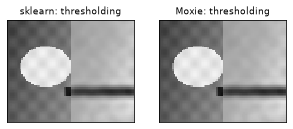

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"extract_patches_2d(left half, (7, 7))",PASS,"(1972, 7, 7)","(1972, 7, 7)",,,exact,0 mismatches,pure copies of Float64 pixels
reconstruct_from_patches_2d(noisy patches),PASS,"(64, 40)","(64, 40)",0,0,"rtol=1e-13, atol=1e-15",,same accumulation order (enumeration order) and overlap counts; division rounding only
threshold code (SparseCoder vs dico.transform),PASS,"(1972, 50)","(1972, 50)",1.33e-15,1.38e-11,"rtol=1e-10, atol=1e-12",,X @ V.T products accumulate in a different order (BLAS vs native); ~1e-15 relative
thresholding reconstruction (right half),PASS,"(64, 40)","(64, 40)",2.22e-16,4.43e-16,"rtol=1e-09, atol=1e-11",,propagates the code/decoding product rounding through min/max scaling and averaging
"extract_patches_2d(max_patches=0.05, random_state=0)",PASS,"(98, 7, 7)","(98, 7, 7)",,,exact,0 mismatches,"same legacy RandomState.randint stream, rows drawn before columns"
"PatchExtractor(max_patches=20, random_state=0).transform(batch)",PASS,"(40, 7, 7)","(40, 7, 7)",,,exact,0 mismatches,"one seeded stream shared across the batch, image-major output"
MiniBatchDictionaryLearning,GAP,,,,,,raising declaration in moxie.decomposition (dense dictionary-learning solver unfinished); the sklearn dictionary is shared as data,
OMP / LARS transform algorithms,GAP,,,,,,SparseCoder implements only threshold; omp/lars raise NotImplementedError (decomposition family),


In [9]:
import moxie_nb

mx = nb.results["denoise"]
moxie_threshold = raccoon_face.copy()
moxie_threshold[:, width // 2 :] = mx["threshold_half"]
fig, axes = plt.subplots(1, 2, figsize=(5, 2.2), dpi=72)
for ax, img, title in [(axes[0], reconstructions["Thresholding\n alpha=0.1"], "sklearn"), (axes[1], moxie_threshold, "Moxie")]:
    ax.imshow(img, vmin=0, vmax=1, cmap=plt.cm.gray, interpolation="nearest")
    ax.set_title(title + ": thresholding", fontsize=9)
    ax.set_xticks(()); ax.set_yticks(())
plt.show()
dico.set_params(transform_algorithm="threshold", transform_alpha=0.1)
sk_code = dico.transform(data)
moxie_nb.side_by_side(sklearn=sk_threshold_half[:4, :6], moxie=mx["threshold_half"][:4, :6])
nb.compare("extract_patches_2d(left half, (7, 7))", sk_left_patches, mx["left_patches"], exact=True,
           reason="pure copies of Float64 pixels")
nb.compare("reconstruct_from_patches_2d(noisy patches)", sk_noisy_rebuilt, mx["noisy_rebuilt"], rtol=1e-13, atol=1e-15,
           reason="same accumulation order (enumeration order) and overlap counts; division rounding only")
nb.compare("threshold code (SparseCoder vs dico.transform)", sk_code, mx["code"], rtol=1e-10, atol=1e-12,
           reason="X @ V.T products accumulate in a different order (BLAS vs native); ~1e-15 relative")
nb.compare("thresholding reconstruction (right half)", sk_threshold_half, mx["threshold_half"], rtol=1e-9, atol=1e-11,
           reason="propagates the code/decoding product rounding through min/max scaling and averaging")
nb.compare("extract_patches_2d(max_patches=0.05, random_state=0)", sk_sampled, mx["sampled"], exact=True,
           reason="same legacy RandomState.randint stream, rows drawn before columns")
nb.compare("PatchExtractor(max_patches=20, random_state=0).transform(batch)", sk_batch, mx["batch"], exact=True,
           reason="one seeded stream shared across the batch, image-major output")
nb.note("MiniBatchDictionaryLearning", "GAP",
        "raising declaration in moxie.decomposition (dense dictionary-learning solver unfinished); "
        "the sklearn dictionary is shared as data")
nb.note("OMP / LARS transform algorithms", "GAP",
        "SparseCoder implements only threshold; omp/lars raise NotImplementedError (decomposition family)")
nb.report()
nb.assert_parity()